# 06 ST-GCN, final results

ST-GCN (Yan et al., 2018) trained under the locked protocol: `body_court` input (notebook 03) and the
tuned recipe (notebook 04), loaded from `configs/stgcn_recipe.json` rather than re-decided here. Six runs:
3 seeds (42, 123, 7) x {augmentation, no augmentation}. This is the first notebook in the project to
evaluate the test set — every prior decision was made on validation alone.

This is also the paper replication: ST-GCN is the architecture Li et al. benchmark, so its augmented,
test set result is the number compared directly against their reported 74.41 / 93.76 / 61.44
(top 1 / top 5 / MCA).

Runs log to `BadmintonPoseAnalysis/models/STGCN`.

In [1]:
import os
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"

import json
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from clearml import Task

REPO = os.environ.get("BADMINTON_REPO", "/workspace/badminton-honours-project")
DATA = os.environ.get("BADMINTON_DATA", "/workspace/data")
sys.path.insert(0, REPO)
import dataset as ds
import training as tr
from models import stgcn

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(torch.__version__, device, torch.cuda.get_device_name(0) if device.type == "cuda" else "")

plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})

2.1.0+cu118 cuda NVIDIA GeForce RTX 4090


In [2]:
PROJECT = "BadmintonPoseAnalysis/models/STGCN"
KEYPOINTS = f"{DATA}/keypoints_interp"
OUT = os.environ.get("BADMINTON_OUTPUTS", "/workspace/outputs") + "/models/stgcn"
os.makedirs(OUT, exist_ok=True)

with open(f"{REPO}/configs/stgcn_recipe.json") as f:
    RECIPE = json.load(f)
print(json.dumps(RECIPE, indent=2))

SEEDS = [42, 123, 7]
AUG_CONDITIONS = {"advanced": "advanced", "none": "none"}
NORMALISATION, USE_COURT = "body", True   # body_court, matches the recipe
NUM_WORKERS = 12

LI_ET_AL_STGCN = {"top1": 0.7441, "top5": 0.9376, "mca": 0.6144}
NO_MOTION_PROBE = {"top1": 0.549, "mca": 0.429}

{
  "model": "ST-GCN",
  "normalisation": "body_court",
  "selected": "combination",
  "changes_from_baseline": {
    "weight_decay": 0.005,
    "target_per_class": 300
  },
  "augmentation": "advanced",
  "min_native_frames": 5,
  "batch_size": 16,
  "lr": 0.01,
  "momentum": 0.9,
  "gamma": 0.1,
  "select_metric": "top1",
  "weight_decay": 0.005,
  "label_smoothing": 0.0,
  "schedule": "step10",
  "target_per_class": 300,
  "num_epochs": 60,
  "patience": 20,
  "tuning": {
    "seeds": [
      11,
      22
    ],
    "val_top1": 0.7612,
    "baseline_val_top1": 0.7394
  }
}


In [3]:
manifest = ds.load_filtered_manifest(f"{DATA}/split_manifest.csv", f"{DATA}/extraction_log.csv",
                                     f"{DATA}/keypoints_interp_log.csv", RECIPE["min_native_frames"])
class_names = sorted(manifest["class_name"].unique())
class_to_id = {c: i for i, c in enumerate(class_names)}
split_hash = open(f"{DATA}/split_manifest.sha256").read().split()[0]
forward = stgcn.make_forward(USE_COURT)
in_channels = 7 if USE_COURT else 5


def make_scheduler(optimizer, schedule):
    if schedule == "step10":
        return torch.optim.lr_scheduler.StepLR(optimizer, step_size=10, gamma=RECIPE["gamma"])
    if schedule == "multistep_25_40":
        return torch.optim.lr_scheduler.MultiStepLR(optimizer, milestones=[25, 40], gamma=RECIPE["gamma"])
    raise ValueError(RECIPE["schedule"])

manual review: dropped 4 clips
short clip rule: dropped 4 train clips with fewer than 5 real frames
7810 clips remain (train 6247, test 782, val 781)


## Smoke test

In [4]:
tr.seed_everything(0)
loaders = tr.build_loaders(manifest, KEYPOINTS, class_to_id, "advanced", NORMALISATION, seed=0,
                           batch_size=RECIPE["batch_size"], target_per_class=RECIPE["target_per_class"],
                           num_workers=2, eval_workers=2)
model = stgcn.build_stgcn(in_channels, len(class_names)).to(device)
batch = next(iter(loaders["train"]))
logits = forward(model, batch, device)
assert logits.shape == (RECIPE["batch_size"], len(class_names))
nn.CrossEntropyLoss(label_smoothing=RECIPE["label_smoothing"])(logits, batch["label"].to(device)).backward()
assert not [n for n, p in model.named_parameters() if p.requires_grad and p.grad is None]
before = tr.evaluate(model, loaders["test"], forward, device)
print(f"params {sum(p.numel() for p in model.parameters()):,}  untrained test top1 {before['top1']:.3f}")
del model, loaders
print("smoke test passed")

params 3,028,283  untrained test top1 0.014
smoke test passed


## Runs

Six runs: three seeds, with and without augmentation. Appends to `results.csv` and skips finished runs.

In [5]:
results_path = f"{OUT}/results.csv"
done = pd.read_csv(results_path) if os.path.exists(results_path) else pd.DataFrame(columns=["augmentation", "seed"])

for aug_name, aug_policy in AUG_CONDITIONS.items():
    for seed in SEEDS:
        if ((done["augmentation"] == aug_name) & (done["seed"] == seed)).any():
            print(f"skip {aug_name} seed {seed}, already done")
            continue
        run_name = f"stgcn_{aug_name}_s{seed}"
        print(f"\n=== {run_name} ===")
        tr.seed_everything(seed)

        task = Task.init(project_name=PROJECT, task_name=run_name, task_type=Task.TaskTypes.training,
                         tags=["final", aug_name, "stgcn", f"seed{seed}"], reuse_last_task_id=False,
                         auto_connect_frameworks={"matplotlib": False, "pytorch": False})
        task.connect({**RECIPE, "augmentation": aug_policy, "seed": seed, "in_channels": in_channels,
                      "keypoints": KEYPOINTS, "split_sha256": split_hash, "normalisation": "body_court",
                      "li_et_al_stgcn": LI_ET_AL_STGCN, "no_motion_probe": NO_MOTION_PROBE})

        loaders = tr.build_loaders(manifest, KEYPOINTS, class_to_id, aug_policy, NORMALISATION, seed=seed,
                                   batch_size=RECIPE["batch_size"], target_per_class=RECIPE["target_per_class"],
                                   num_workers=NUM_WORKERS)
        model = stgcn.build_stgcn(in_channels, len(class_names)).to(device)
        optimizer = torch.optim.SGD(model.parameters(), lr=RECIPE["lr"], momentum=RECIPE["momentum"],
                                    weight_decay=RECIPE["weight_decay"])
        scheduler = make_scheduler(optimizer, RECIPE["schedule"])
        criterion = nn.CrossEntropyLoss(label_smoothing=RECIPE["label_smoothing"])

        _, history, best_epoch = tr.train_model(model, forward, loaders, optimizer, scheduler, criterion, device,
                                                task.get_logger(), num_epochs=RECIPE["num_epochs"],
                                                patience=RECIPE["patience"], select_metric=RECIPE["select_metric"])
        metrics = tr.report_run(task, model, forward, loaders, class_names, device, history, best_epoch,
                                out_dir=f"{OUT}/{run_name}", run_name=run_name, show=False,
                                extra={"augmentation": aug_name, "seed": seed})
        task.close()

        done = pd.concat([done, pd.DataFrame([metrics])], ignore_index=True)
        done.to_csv(results_path, index=False)
        del model, loaders
        torch.cuda.empty_cache()


=== stgcn_advanced_s42 ===
ClearML Task: created new task id=326ea06e914849aaac34bd14b4a6a7b7
2026-09-29 10:04:32,647 - clearml.Repository Detection - WARNING - Failed accessing the jupyter server(s): []
ClearML results page: https://app.clear.ml/projects/23df26f6d3e54aa9a4edc4761cccc6b1/tasks/326ea06e914849aaac34bd14b4a6a7b7/output/log
epoch   0  loss 1.960  train 0.592  val 0.567 (mca 0.416)  *
epoch   1  loss 1.524  train 0.612  val 0.608 (mca 0.517)  *
epoch   2  loss 1.391  train 0.643  val 0.650 (mca 0.572)  *
epoch   4  loss 1.235  train 0.667  val 0.654 (mca 0.539)  *
epoch   5  loss 1.189  train 0.668  val 0.654 (mca 0.537)
epoch   6  loss 1.181  train 0.692  val 0.677 (mca 0.557)  *
epoch  10  loss 0.889  train 0.779  val 0.731 (mca 0.646)  *
epoch  15  loss 0.638  train 0.845  val 0.721 (mca 0.639)
epoch  20  loss 0.431  train 0.914  val 0.743 (mca 0.648)  *
epoch  21  loss 0.375  train 0.926  val 0.744 (mca 0.638)  *
epoch  25  loss 0.321  train 0.952  val 0.745 (mca 0.647

███████████████████████████████ 100% | 11.66/11.66 MB [00:03<00:00,  3.85MB/s]: 



=== stgcn_advanced_s123 ===


Failed accessing the jupyter server(s): []


ClearML Task: created new task id=66b9631514c74014958e303c3d4eb897
ClearML results page: https://app.clear.ml/projects/23df26f6d3e54aa9a4edc4761cccc6b1/tasks/66b9631514c74014958e303c3d4eb897/output/log
epoch   0  loss 1.983  train 0.535  val 0.517 (mca 0.383)  *
epoch   1  loss 1.492  train 0.630  val 0.627 (mca 0.496)  *
epoch   3  loss 1.264  train 0.655  val 0.653 (mca 0.557)  *
epoch   4  loss 1.212  train 0.689  val 0.690 (mca 0.576)  *
epoch   5  loss 1.184  train 0.669  val 0.644 (mca 0.562)
epoch  10  loss 0.902  train 0.786  val 0.718 (mca 0.632)  *
epoch  11  loss 0.800  train 0.801  val 0.730 (mca 0.639)  *
epoch  15  loss 0.618  train 0.840  val 0.721 (mca 0.639)
epoch  20  loss 0.408  train 0.924  val 0.730 (mca 0.640)
epoch  21  loss 0.362  train 0.934  val 0.743 (mca 0.643)  *
epoch  22  loss 0.338  train 0.941  val 0.749 (mca 0.651)  *
epoch  25  loss 0.300  train 0.958  val 0.745 (mca 0.644)
epoch  30  loss 0.242  train 0.972  val 0.741 (mca 0.640)
epoch  35  loss 0.23

...

███████████████████████████████ 100% | 11.66/11.66 MB [00:02<00:00,  4.57MB/s]: 



=== stgcn_none_s7 ===


Failed accessing the jupyter server(s): []


ClearML Task: created new task id=278f88d8d2e746829a77a40377b00858
ClearML results page: https://app.clear.ml/projects/23df26f6d3e54aa9a4edc4761cccc6b1/tasks/278f88d8d2e746829a77a40377b00858/output/log
epoch   0  loss 1.977  train 0.601  val 0.576 (mca 0.421)  *
epoch   1  loss 1.492  train 0.663  val 0.670 (mca 0.541)  *
epoch   3  loss 1.230  train 0.688  val 0.676 (mca 0.555)  *
epoch   5  loss 1.131  train 0.647  val 0.612 (mca 0.549)
epoch  10  loss 0.811  train 0.802  val 0.730 (mca 0.656)  *
epoch  11  loss 0.710  train 0.826  val 0.741 (mca 0.648)  *
epoch  15  loss 0.525  train 0.869  val 0.721 (mca 0.625)
epoch  20  loss 0.291  train 0.960  val 0.736 (mca 0.629)
epoch  25  loss 0.176  train 0.986  val 0.738 (mca 0.636)
epoch  29  loss 0.143  train 0.993  val 0.743 (mca 0.631)  *
epoch  30  loss 0.131  train 0.993  val 0.727 (mca 0.626)
epoch  35  loss 0.127  train 0.996  val 0.735 (mca 0.634)
epoch  40  loss 0.123  train 0.996  val 0.729 (mca 0.633)
epoch  45  loss 0.118  tra

███████████████████████████████ 100% | 11.66/11.66 MB [00:02<00:00,  5.04MB/s]: 


## Summary

In [6]:
results = pd.read_csv(results_path)
summary_task = Task.init(project_name=PROJECT, task_name="stgcn_summary", task_type=Task.TaskTypes.qc,
                         tags=["final", "summary"], reuse_last_task_id=False, auto_connect_frameworks={"matplotlib": False})
slog = summary_task.get_logger()
summary_task.connect({**RECIPE, "seeds": SEEDS, "li_et_al_stgcn": LI_ET_AL_STGCN, "no_motion_probe": NO_MOTION_PROBE})
summary_task.upload_artifact("results", artifact_object=results_path)

metric_cols = ["test_top1", "test_top5", "test_mca", "test_macro_f1", "val_top1", "train_test_gap"]
table = tr.mean_std_table(results, ["augmentation"], metric_cols).set_index("augmentation").loc[list(AUG_CONDITIONS)].reset_index()
slog.report_table("ST-GCN final results (mean ± std over 3 seeds)", "test", iteration=0, table_plot=table)
for aug_name in AUG_CONDITIONS:
    sub = results[results["augmentation"] == aug_name]
    for m in ["test_top1", "test_top5", "test_mca", "test_macro_f1"]:
        slog.report_single_value(f"{aug_name}_{m}_mean", float(sub[m].mean()))
table

Failed accessing the jupyter server(s): []


ClearML Task: created new task id=f9245dcf3ce64620908346405b90ec74
ClearML results page: https://app.clear.ml/projects/23df26f6d3e54aa9a4edc4761cccc6b1/tasks/f9245dcf3ce64620908346405b90ec74/output/log


,augmentation,test_top1,test_top5,test_mca,test_macro_f1,val_top1,train_test_gap,seeds
0,advanced,72.29 ± 1.06,94.37 ± 0.13,61.21 ± 1.33,62.31 ± 1.94,74.78 ± 0.13,23.52 ± 2.45,3
1,none,71.95 ± 0.63,94.25 ± 0.68,58.65 ± 2.83,60.72 ± 2.65,74.61 ± 0.71,27.46 ± 0.62,3


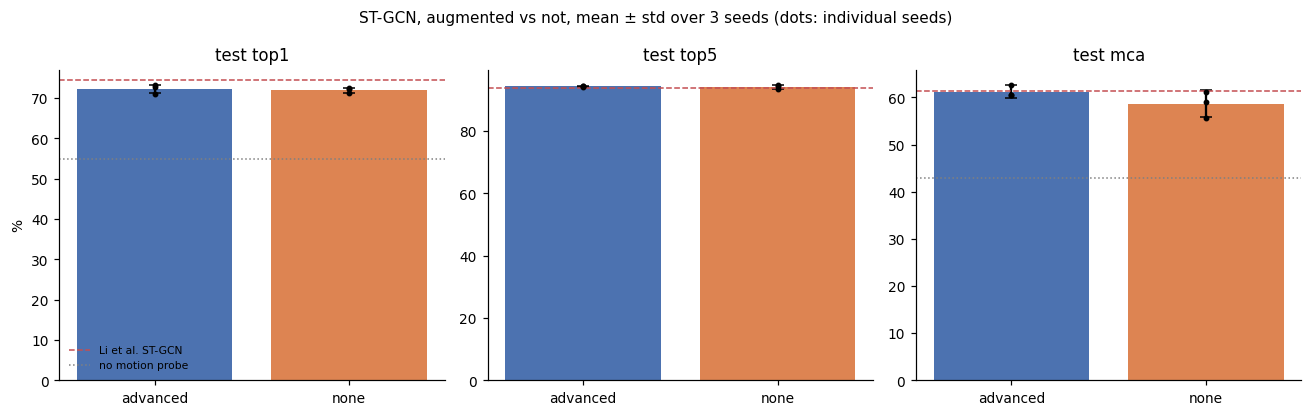

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
x = np.arange(len(AUG_CONDITIONS))
colours = ["#4c72b0", "#dd8452"]
for ax, m, ref_key in zip(axes, ["test_top1", "test_top5", "test_mca"], ["top1", "top5", "mca"]):
    g = results.groupby("augmentation")[m]
    means, stds = g.mean().loc[list(AUG_CONDITIONS)], g.std().loc[list(AUG_CONDITIONS)]
    ax.bar(x, 100 * means, yerr=100 * stds, capsize=4, color=colours)
    for i, name in enumerate(AUG_CONDITIONS):
        ax.scatter(np.full(len(SEEDS), i), 100 * results.loc[results["augmentation"] == name, m], color="black", s=8, zorder=3)
    ax.axhline(100 * LI_ET_AL_STGCN[ref_key], color="#c44e52", ls="--", lw=1, label="Li et al. ST-GCN")
    if ref_key in NO_MOTION_PROBE:
        ax.axhline(100 * NO_MOTION_PROBE[ref_key], color="grey", ls=":", lw=1, label="no motion probe")
    ax.set_xticks(x, list(AUG_CONDITIONS))
    ax.set_title(m.replace("test_", "test ").replace("_", " "))
axes[0].set_ylabel("%")
axes[0].legend(frameon=False, fontsize=7)
fig.suptitle("ST-GCN, augmented vs not, mean ± std over 3 seeds (dots: individual seeds)", fontsize=10)
fig.tight_layout()
slog.report_matplotlib_figure("augmentation comparison", "test", figure=fig, iteration=0, report_interactive=False)
plt.show()

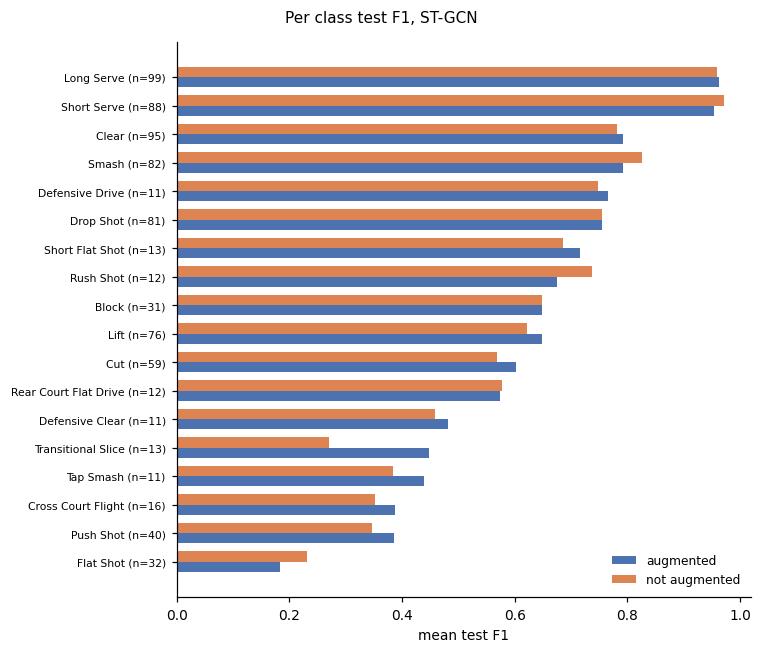

In [8]:
per_class = []
for _, r in results.iterrows():
    pc = pd.read_csv(f"{OUT}/{r['run']}/{r['run']}_per_class.csv")
    pc["augmentation"] = r["augmentation"]
    per_class.append(pc)
per_class = pd.concat(per_class)
f1_by_class = per_class.groupby(["class", "augmentation"])["f1"].mean().unstack()[list(AUG_CONDITIONS)]
support = per_class.groupby("class")["support"].first()
f1_by_class = f1_by_class.assign(support=support).sort_values("advanced")

fig, ax = plt.subplots(figsize=(7, 6))
y = np.arange(len(f1_by_class))
ax.barh(y - 0.18, f1_by_class["advanced"], height=0.36, color="#4c72b0", label="augmented")
ax.barh(y + 0.18, f1_by_class["none"], height=0.36, color="#dd8452", label="not augmented")
ax.set_yticks(y, [f"{c} (n={n})" for c, n in zip(f1_by_class.index, f1_by_class["support"])], fontsize=7)
ax.set_xlabel("mean test F1")
ax.legend(frameon=False, fontsize=8)
fig.suptitle("Per class test F1, ST-GCN", fontsize=10)
fig.tight_layout()
slog.report_matplotlib_figure("per class F1, augmented vs not", "test", figure=fig, iteration=0, report_interactive=False)
plt.show()
slog.report_table("per class F1", "test", iteration=0, table_plot=f1_by_class.reset_index())

## Best single run

The confusion matrix and learning curves of the best augmented run, for the results chapter.

stgcn_advanced_s7 test top1 0.7315


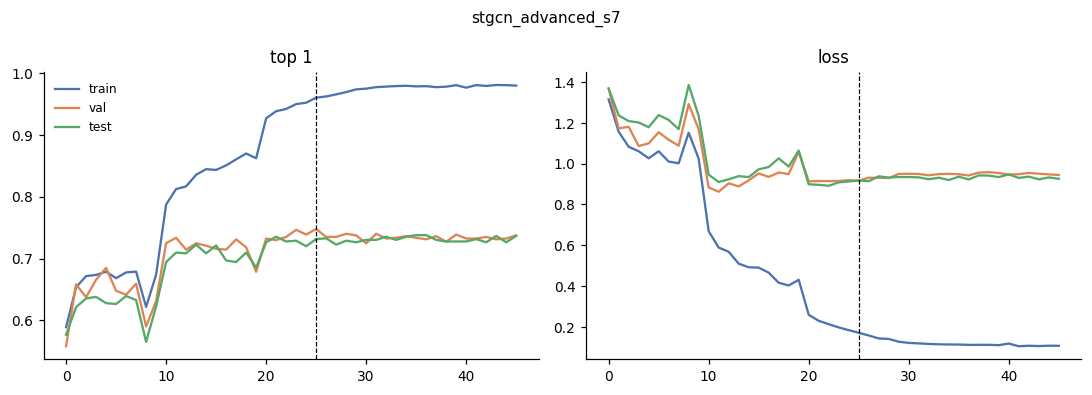

In [9]:
best_run = results[results["augmentation"] == "advanced"].sort_values("test_top1", ascending=False).iloc[0]
print(best_run["run"], f"test top1 {best_run['test_top1']:.4f}")

hist = pd.read_csv(f"{OUT}/{best_run['run']}/{best_run['run']}_history.csv")
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for s, colour in [("train", "#4c72b0"), ("val", "#dd8452"), ("test", "#55a868")]:
    axes[0].plot(hist["epoch"], hist[f"{s}_top1"], color=colour, label=s)
    axes[1].plot(hist["epoch"], hist[f"{s}_loss"], color=colour, label=s)
axes[0].axvline(best_run["best_epoch"], color="black", ls="--", lw=0.8)
axes[1].axvline(best_run["best_epoch"], color="black", ls="--", lw=0.8)
axes[0].set_title("top 1")
axes[1].set_title("loss")
axes[0].legend(frameon=False, fontsize=8)
fig.suptitle(best_run["run"], fontsize=10)
fig.tight_layout()
slog.report_matplotlib_figure("best run learning curves", "test", figure=fig, iteration=0, report_interactive=False)
plt.show()
summary_task.close()

## Comparison with Li et al. (2024)

| metric | this work (advanced, mean ± std) | Li et al. ST-GCN |
|---|---|---|
| top 1 | see table above | 74.41 |
| top 5 | see table above | 93.76 |
| MCA | see table above | 61.44 |

Differences from their setup: pose extraction (YOLOv8 + ByteTrack + RTMPose here vs their pipeline),
`body_court` input rather than raw pixels, and a class balanced sampler that trades some majority class
top 1 for MCA. The no motion probe (54.9 top 1, 42.9 MCA, notebook 01) is the floor: any model below it
would be doing worse than court position and clip length alone.